# 03 - Data preprocessing (corrected)

What changed compared with the first version, and why:

1. **Correct test labels.** Test engines are cut *before* failure. The true RUL of a test row is
   `RUL_FD001[engine] + (last_observed_cycle - cycle)`. The old notebook used `max_cycle - cycle` inside the
   truncated test file and never used `RUL_FD001.txt`, so every test metric was meaningless.
2. **Capped target.** RUL is capped at 125 cycles: in the early life of an engine nothing in the sensors tells
   a 300-cycle-remaining engine from a 200-cycle one. Training on 0-361 forces the models to fit noise.
3. **14 sensors only.** Constant sensors and the 3 operating settings (FD001 has one operating condition) are dropped.
4. **Scaler fitted on training engines only.**

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

# Find the project root (the folder containing utils.py) no matter where the kernel was started.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "utils.py").exists())
sys.path.insert(0, str(ROOT))

import numpy as np, pandas as pd, joblib
import matplotlib.pyplot as plt
import utils as U

In [2]:
train, test, rul_last = U.load_raw()
print(train.shape, test.shape)

# --- sanity check of the new test labels ------------------------------------------------------
last = test.sort_values(["unit_id", "cycle"]).groupby("unit_id").tail(1)
assert (last["RUL"].to_numpy() == rul_last["RUL"].to_numpy()).all()
print("last-cycle RUL of every test engine matches RUL_FD001.txt")

old_label = test.groupby("unit_id")["cycle"].transform("max") - test["cycle"]
print("old (wrong) label at the last cycle is always 0; true value ranges",
      last["RUL"].min(), "-", last["RUL"].max())

(20631, 27) (13096, 27)
last-cycle RUL of every test engine matches RUL_FD001.txt
old (wrong) label at the last cycle is always 0; true value ranges 7 - 145


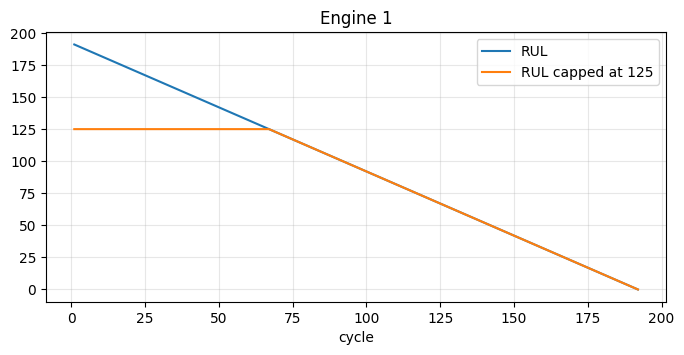

In [3]:
# --- effect of capping on one engine -------------------------------------------------------
e = train[train.unit_id == 1]
plt.figure(figsize=(8, 3.5))
plt.plot(e["cycle"], e["RUL"], label="RUL")
plt.plot(e["cycle"], e["RUL"].clip(upper=U.RUL_CAP), label=f"RUL capped at {U.RUL_CAP}")
plt.xlabel("cycle"); plt.legend(); plt.grid(alpha=0.3); plt.title("Engine 1"); plt.show()

In [4]:
print("Features used:", U.FEATURES)

from sklearn.preprocessing import StandardScaler
scaler = StandardScaler().fit(train[U.FEATURES])
joblib.dump(scaler, U.MODEL_DIR / "scaler.pkl")
print("saved", U.MODEL_DIR / "scaler.pkl")

Features used: ['sensor_2', 'sensor_3', 'sensor_4', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']
saved /home/aryan/tt/NASA-C-MAPSS/claud/models/scaler.pkl


In [5]:
# Inspectable copies of the processed data (the model notebooks rebuild them with U.load_dataset()).
out = U.ROOT / "data" / "processed"; out.mkdir(parents=True, exist_ok=True)
for name, df in (("train", train), ("test", test)):
    p = df[["unit_id", "cycle"]].copy()
    p[U.FEATURES] = scaler.transform(df[U.FEATURES])
    p["RUL"] = df["RUL"]
    p["RUL_capped"] = df["RUL"].clip(upper=U.RUL_CAP)
    p.to_csv(out / f"{name}_processed.csv", index=False)
print("saved processed CSVs to", out)

saved processed CSVs to /home/aryan/tt/NASA-C-MAPSS/claud/data/processed


Notes: the old files in `data/processed/` (`x_train.csv`, `y_test.csv`, ...) are obsolete and can be deleted.
The sequence model builds its 30-cycle windows inside `utils.make_windows` (per engine, no leakage between engines).